# Отложенная проверка зафиксированного решения

Сравниваем два заранее выбранных варианта на 1301–1307. Добавление 10 мест ALS повысило Recall на 0,172 п. п. и снизило NDCG.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/06_final_results'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("06_final_results")
result_table = session.metrics("06_final_results")
if MODE == 'train':
    display(result_table)

Используем сохранённые результаты.


## Результаты отложенной проверки

Квота ALS и остальные параметры зафиксированы до оценки на 1301–1307.

## Зафиксированные условия

Цели — дни 1301–1307, пропуск — день 1300. Сравниваем personal_pop28 и его объединение с ALS, квота 10 мест.

In [3]:
frozen = read('closing_checks_20261107__final_protocol_frozen.json')
display(pd.Series(frozen))
final = read('closing_checks_20261107__final_comparison.csv')
display(final[['method','users','users_with_reachable','recall_reachable@200','recall_all@200','ndcg@200']])

anchor                                                        1301
gap_day                                                       1300
goal_days                                             [1301, 1307]
training_days                                         [1210, 1299]
history_days                                                    60
cohort                   Original80018 users selected on1202..1261
catalog          Observed in original cohort past90; catalog ro...
baseline           Strong personal frequency dailymax60 then pop28
challenger       Same baseline plus raw ALS using existing weig...
als              {'factors': 32, 'regularization': 0.1, 'iterat...
confidence         1+20log1p(sum of daily maximum action strength)
query            Exact full60 all-action collapse consecutive r...
goal                    Unique weekly click items, repeats allowed
metrics          [macro reachable Recall200, macro all Recall20...
decision         Report challenger minus baseline with95%paire

,method,users,users_with_reachable,recall_reachable@200,recall_all@200,ndcg@200
0,personal_pop28,3503,3481,0.195524,0.183649,0.068358
1,personal_als_b10,3503,3481,0.197242,0.185358,0.065778


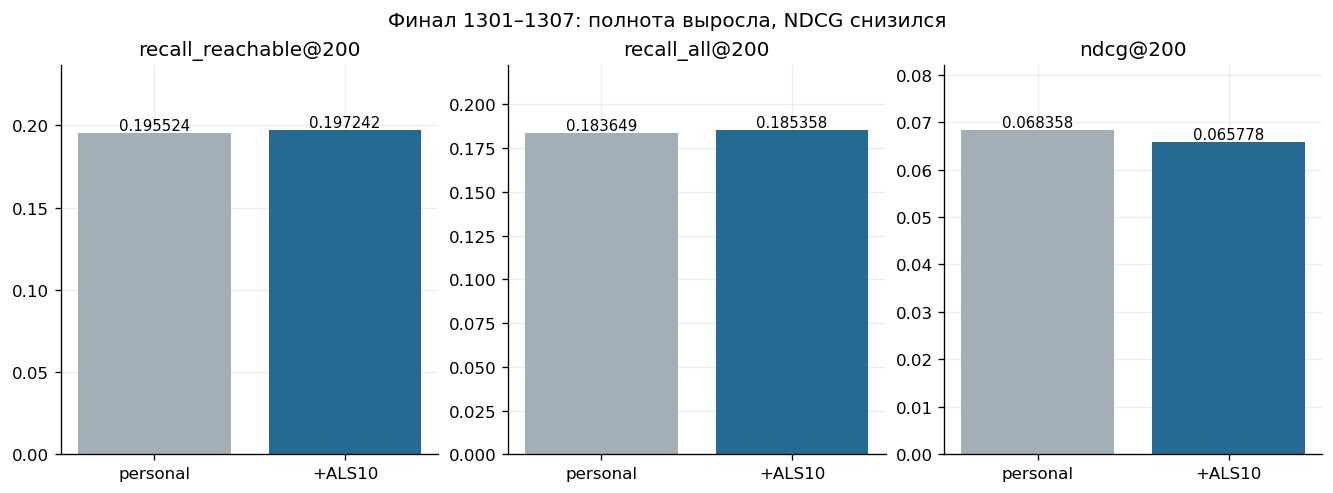

In [4]:
final = read('closing_checks_20261107__final_comparison.csv')
metrics=['recall_reachable@200','recall_all@200','ndcg@200']
fig,axes=plt.subplots(1,3,figsize=(11,4))
for ax,metric in zip(axes,metrics):
    values=final[metric].to_numpy()
    ax.bar(['personal','+ALS10'],values,color=['#A4AEB6','#246A92'])
    ax.set(title=metric,ylim=(0,values.max()*1.2))
    for x,v in enumerate(values):ax.text(x,v,f'{v:.6f}',ha='center',va='bottom',fontsize=9)
fig.suptitle('Финал 1301–1307: полнота выросла, NDCG снизился')
save_figure(fig, figures / 'final_metrics.png')
plt.show()

## Повторный расчёт парной разности

По сохранённым метрикам каждого пользователя повторно считаем среднюю разность и bootstrap-интервал. Пользовательские ID для этого не нужны.

In [5]:
paired = read('paired_metrics.csv')
recalculated = paired_bootstrap(paired.base_recall,paired.als10_recall,repetitions=2000,seed=2026)
original = read('closing_checks_20261107__final_paired_difference.json')
assert np.isclose(recalculated['delta'],original['delta'],atol=1e-12)
assert recalculated['paired_users'] == 3481
print('Сохранённый первичный интервал:',original)
print('Повторный аналитический пересчёт:',recalculated)
print('Δ NDCG:',(paired.als10_ndcg-paired.base_ndcg).mean())

Сохранённый первичный интервал: {'delta': 0.0017174824066605839, 'low95': 0.0005730383925696282, 'high95': 0.0029759243423800458, 'paired_users': 3481, 'bootstrap_repetitions': 2000}
Повторный аналитический пересчёт: {'delta': 0.0017174824066605839, 'low95': 0.0005394290968563405, 'high95': 0.0030334785348225457, 'paired_users': 3481, 'repetitions': 2000, 'seed': 2026}
Δ NDCG: -0.002579833622681044


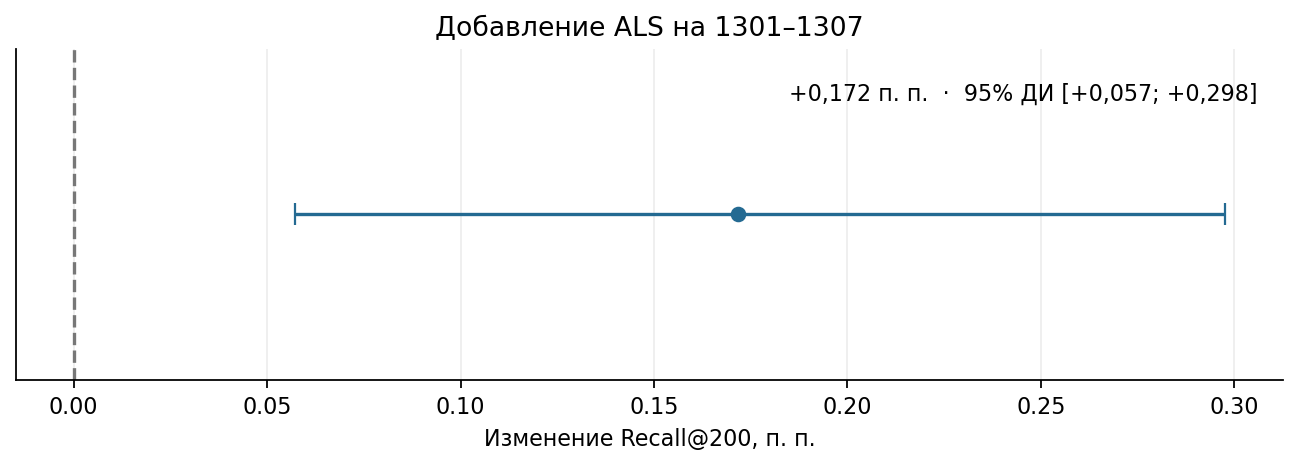

In [6]:
original = read('closing_checks_20261107__final_paired_difference.json')
delta, lo, hi = (100 * original[key] for key in ('delta', 'low95', 'high95'))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.errorbar([delta], [0], xerr=[[delta - lo], [hi - delta]], fmt='o', capsize=5, color='#246A92')
ax.axvline(0, color='#777777', ls='--')
ax.set(yticks=[], ylim=(-0.6, 0.6), xlabel='Изменение Recall@200, п. п.',
       title='Добавление ALS на 1301–1307')
format_pp = lambda value: f'{value:+.3f}'.replace('.', ',')
ax.text(0.98, 0.90, f'{format_pp(delta)} п. п.  ·  95% ДИ [{format_pp(lo)}; {format_pp(hi)}]',
        transform=ax.transAxes, ha='right', va='top')
save_figure(fig, figures / 'paired_difference.png')
plt.show()

## Время расчёта и проверка метрик

Показаны время ALS и результат отдельного пересчёта по сохранённым целям и выдачам. Время personal отдельно не измерялось.

In [7]:
display(final[['method','fit_seconds','als_predict_seconds']])
audit = read('closing_checks_20261107__final_independent_audit.json')
display(audit)

,method,fit_seconds,als_predict_seconds
0,personal_pop28,0.000000,43.817201
1,personal_als_b10,32.268698,43.817201


{'passed': True,
 'queries': 3503,
 'reachable_queries': 3481,
 'added_target_pairs': 32,
 'lost_target_pairs': 15,
 'independently_recounted_delta': 0.001717482406660584,
 'full_delta': 0.001708376259911868,
 'exact200_unique_in_catalog': True,
 'goals_read_from_verified7files': True}

## Вывод

Квота ALS в 10 мест повысила Recall на 0,172 процентного пункта. NDCG снизился с 0,0684 до 0,0658.